# Codigo final V2: DroneFace + ArcFace con graficos livianos

## 0. Especificacion de diseno y protocolo

Este notebook mantiene un unico flujo final, pero separa dos modos de trabajo:

- **Pipeline pesado**: construye galerias, inicializa ArcFace/InsightFace, calcula embeddings, detecta rostros y evalua.
- **Analisis liviano**: lee CSV ya guardados en `outputs_v2/`, regenera tablas/graficos y muestra resultados.

Por defecto, el notebook queda en modo liviano:

```python
RUN_HEAVY_PIPELINE = False
REGENERATE_FIGURES = True
```

Con `RUN_HEAVY_PIPELINE = False`, el notebook no inicializa InsightFace y no recalcula embeddings ni detecciones.

### Decision metodologica principal

No se ajustan los pesos de ArcFace. InsightFace/ArcFace se usa como modelo preentrenado (`buffalo_l`). Cuando se habla de "entrenar", significa construir galerias de embeddings de referencia.

### Galerias V2

Las galerias se construyen desde `trio_cam + trio_gp`, porque cubren los 11 sujetos (`a` a `k`) y tres poses por sujeto:

```text
trio_front = porF
trio_side  = porL + porR
trio_all   = porF + porL + porR
```

`photos_all_faces` ya esta etiquetado por nombre de archivo. `photos_all` usa la anotacion manual de orden espacial en `outputs_v2/annotations/photos_all_spatial_order_manual.csv`.

### Repeticiones e incertidumbre

No se reporta media/desviacion estandar de multiples corridas, porque el pipeline actual es deterministico: mismo modelo, mismos datos y mismas galerias producen los mismos resultados. Se reportan metricas puntuales: accuracy, precision, recall, F1, TP, FP y FN.

Todos los resultados nuevos se guardan en `outputs_v2/`. La carpeta `outputs/` queda intacta.

## 1. Librerias, flags y configuracion

In [12]:
from pathlib import Path

from IPython.display import Image as NotebookImage, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import DRONEFACE_ROOT, PROJECT_ROOT
from src.v2_figures import (
    GALLERY_NAMES,
    OUTPUTS_V2_DIR,
    V2_FIGS_DIR,
    V2_RESULTS_DIR,
    V2_TABLES_DIR,
    bbox_top_level_metrics,
    load_v2_light_results,
    regenerate_v2_figures,
)

pd.set_option("display.max_columns", 140)
pd.set_option("display.width", 180)

RUN_HEAVY_PIPELINE = False
REGENERATE_FIGURES = True

FACE_DET_SIZE = (320, 320)
FULL_IMAGE_DET_SIZE = (1280, 1280)

print(f"Project root: {PROJECT_ROOT}")
print(f"DroneFace root: {DRONEFACE_ROOT}")
print(f"V2 outputs: {OUTPUTS_V2_DIR}")
print(f"RUN_HEAVY_PIPELINE={RUN_HEAVY_PIPELINE}")
print(f"REGENERATE_FIGURES={REGENERATE_FIGURES}")

Project root: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros
DroneFace root: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\data\DroneFace\open_data_set
V2 outputs: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs_v2
RUN_HEAVY_PIPELINE=False
REGENERATE_FIGURES=True


## 2. Indice de DroneFace

In [13]:
drone_index_v2_path = V2_TABLES_DIR / "droneface_index_v2.csv"

if RUN_HEAVY_PIPELINE:
    from src.dataset_index import inspect_droneface_dataset, build_droneface_index
    from src.v2_protocol import select_photos_all_faces_probes

    drone_info = inspect_droneface_dataset(DRONEFACE_ROOT, n_examples=12)
    drone_df = build_droneface_index(DRONEFACE_ROOT, save=False)
    drone_index_v2_path.parent.mkdir(parents=True, exist_ok=True)
    drone_df.to_csv(drone_index_v2_path, index=False)
    print(f"Indice V2 guardado en: {drone_index_v2_path}")

    trio_counts = (
        drone_df[drone_df["source_folder"].isin(["trio_cam", "trio_gp"])]
        .groupby(["source_folder", "subject_id", "image_type"], dropna=False)
        .size()
        .reset_index(name="n")
        .sort_values(["source_folder", "subject_id", "image_type"])
    )
    for source in ["trio_cam", "trio_gp"]:
        subset = trio_counts[trio_counts["source_folder"] == source]
        assert len(subset) == 33, f"{source}: se esperaban 11 sujetos x 3 poses"
        assert subset["subject_id"].nunique() == 11, f"{source}: se esperaban 11 sujetos"
        assert sorted(subset["image_type"].unique()) == ["porF", "porL", "porR"]
        assert (subset["n"] == 1).all(), f"{source}: alguna combinacion sujeto-pose no tiene 1 imagen"
    print("Validacion trio_cam/trio_gp OK: 11 sujetos x 3 poses en cada fuente.")
    print(f"photos_all_faces probes disponibles: {len(select_photos_all_faces_probes(drone_df))}")
else:
    if drone_index_v2_path.exists():
        drone_df = pd.read_csv(drone_index_v2_path)
        print(f"Indice V2 cargado desde: {drone_index_v2_path}")
    else:
        drone_df = pd.DataFrame()
        print("No existe droneface_index_v2.csv. Para reconstruirlo, usa RUN_HEAVY_PIPELINE=True.")

if not drone_df.empty:
    display(
        drone_df.groupby(["source_folder", "split"], dropna=False)
        .size()
        .reset_index(name="n")
        .sort_values(["source_folder", "split"])
    )

Indice V2 cargado desde: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs_v2\tables\droneface_index_v2.csv


,source_folder,split,n
0,photos_all,unused,620
1,photos_all_faces,probe,1364
2,portraits,gallery,7
3,trio_cam,unused,33
4,trio_gp,unused,33


## 3. Pipeline pesado opcional: Experimento A V2

Esta seccion solo corre si `RUN_HEAVY_PIPELINE=True`. Construye las galerias `trio_front`, `trio_side` y `trio_all`, y evalua `photos_all_faces`.

In [14]:
gallery_outputs = None
pose_comparison_df = None
gallery_info_df = None

if RUN_HEAVY_PIPELINE:
    from src.face_model import FaceRecognizerArcFace
    from src.v2_protocol import run_pose_gallery_experiments

    model_faces = FaceRecognizerArcFace(model_name="buffalo_l", det_size=FACE_DET_SIZE, allow_cuda=False)
    print(f"Modelo A inicializado con det_size={model_faces.det_size}")

    gallery_outputs, pose_comparison_df, gallery_info_df = run_pose_gallery_experiments(
        drone_df,
        model_faces,
    )
    display(pose_comparison_df)
    display(gallery_info_df.head(20))
else:
    print("Saltado: RUN_HEAVY_PIPELINE=False. Se usaran los CSV de outputs_v2 en las secciones livianas.")

Saltado: RUN_HEAVY_PIPELINE=False. Se usaran los CSV de outputs_v2 en las secciones livianas.


## 4. Pipeline pesado opcional: Experimento B V2

Esta seccion solo corre si `RUN_HEAVY_PIPELINE=True`. Evalua `photos_all` completo con las galerias construidas en el Experimento A.

In [15]:
full_outputs = None
full_set_summary_df = None

if RUN_HEAVY_PIPELINE:
    from src.face_model import FaceRecognizerArcFace
    from src.v2_protocol import run_full_image_set_experiments

    if gallery_outputs is None:
        raise RuntimeError("Primero debe ejecutarse el Experimento A pesado para construir gallery_outputs.")

    model_full = FaceRecognizerArcFace(model_name="buffalo_l", det_size=FULL_IMAGE_DET_SIZE, allow_cuda=False)
    print(f"Modelo B inicializado con det_size={model_full.det_size}")

    full_outputs, full_set_summary_df = run_full_image_set_experiments(
        drone_df,
        model_full,
        gallery_outputs,
    )
    display(full_set_summary_df)
else:
    print("Saltado: RUN_HEAVY_PIPELINE=False.")

Saltado: RUN_HEAVY_PIPELINE=False.


## 5. Pipeline pesado opcional: bbox-level con anotacion manual

Esta seccion solo corre si `RUN_HEAVY_PIPELINE=True`. Usa el orden espacial manual de `photos_all` y calcula TP, FP, FN, precision, recall y F1 por bounding box.

In [16]:
bbox_ready = False
labeled_bbox_df = None
bbox_metrics_df = None

if RUN_HEAVY_PIPELINE:
    from src.v2_protocol import (
        V2_ANNOTATIONS_DIR,
        create_spatial_annotation_template,
        run_bbox_level_if_annotations_complete,
        validate_spatial_annotation,
    )

    annotation_path = create_spatial_annotation_template(
        V2_ANNOTATIONS_DIR / "photos_all_spatial_order_manual.csv",
        overwrite=False,
    )
    annotation_df, annotation_complete, annotation_errors = validate_spatial_annotation(annotation_path)
    print(f"Anotacion manual: {annotation_path}")
    print(f"Completa: {annotation_complete}")
    display(annotation_df)

    if full_outputs is None:
        raise RuntimeError("Primero debe ejecutarse el Experimento B pesado para construir full_outputs.")

    bbox_ready, labeled_bbox_df, bbox_metrics_df, bbox_errors = run_bbox_level_if_annotations_complete(
        drone_df,
        full_outputs,
        annotation_path=annotation_path,
    )
    if not bbox_ready:
        print("BBox-level omitido: la anotacion manual aun no esta completa.")
        for error in bbox_errors:
            print(f"- {error}")
    else:
        display(bbox_metrics_df)
else:
    print("Saltado: RUN_HEAVY_PIPELINE=False.")

Saltado: RUN_HEAVY_PIPELINE=False.


## 6. Resultados livianos desde `outputs_v2`

Desde aqui no se inicializa InsightFace. Esta parte carga resultados ya calculados y permite ajustar tablas/graficos rapidamente.

In [17]:
light_results = load_v2_light_results()

pose_comparison_df = light_results.pose_comparison
full_set_summary_df = light_results.full_set_summary
bbox_metrics_df = light_results.bbox_metrics
labeled_bbox_df = light_results.labeled_bbox

print("Experimento A: photos_all_faces")
display(
    pose_comparison_df[
        [
            "gallery_name",
            "poses",
            "gallery_rows",
            "gallery_subjects_with_embedding",
            "total_probe",
            "detected_count",
            "detection_rate",
            "correct_count",
            "accuracy_global",
            "accuracy_conditional",
        ]
    ]
)

print("Experimento B: photos_all por conjunto de identidades")
display(
    full_set_summary_df[
        [
            "gallery_name",
            "total_images",
            "images_with_detections",
            "image_detection_rate",
            "expected_identity_recall_global",
            "exact_expected_set_match_rate",
            "mean_jaccard_set_similarity",
        ]
    ]
)

print("Experimento B bbox-level")
bbox_top_df = bbox_top_level_metrics(bbox_metrics_df)
display(bbox_top_df[["gallery_name", "total_slots", "tp", "fp", "fn", "precision", "recall", "f1"]])

Experimento A: photos_all_faces


,gallery_name,poses,gallery_rows,gallery_subjects_with_embedding,total_probe,detected_count,detection_rate,correct_count,accuracy_global,accuracy_conditional
0,trio_front,porF,22,11,1364,1350,0.989736,1316,0.964809,0.974815
1,trio_side,"porL,porR",44,11,1364,1350,0.989736,1282,0.939883,0.949630
2,trio_all,"porF,porL,porR",66,11,1364,1350,0.989736,1313,0.962610,0.972593


Experimento B: photos_all por conjunto de identidades


,gallery_name,total_images,images_with_detections,image_detection_rate,expected_identity_recall_global,exact_expected_set_match_rate,mean_jaccard_set_similarity
0,trio_front,620,567,0.914516,0.784457,0.643548,0.772177
1,trio_side,620,567,0.914516,0.769795,0.625806,0.752151
2,trio_all,620,567,0.914516,0.780059,0.638710,0.765726


Experimento B bbox-level


,gallery_name,total_slots,tp,fp,fn,precision,recall,f1
0,trio_all,1394,985,138,379,0.877115,0.722141,0.792119
1,trio_front,1394,992,131,372,0.883348,0.727273,0.797748
2,trio_side,1394,970,153,394,0.863758,0.711144,0.780056


## 7. Regeneracion liviana de graficos

In [18]:
if REGENERATE_FIGURES:
    figure_paths = regenerate_v2_figures(light_results)
    print(f"Graficos regenerados: {len(figure_paths)}")
else:
    figure_paths = sorted((V2_FIGS_DIR / "metrics").glob("*.png"))
    print(f"Graficos existentes encontrados: {len(figure_paths)}")

display(pd.DataFrame({"figure_path": [str(path) for path in figure_paths]}))

Graficos regenerados: 31


,figure_path
0,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...
1,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...
2,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...
3,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...
4,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...
5,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...
6,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...
7,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...
8,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...
9,C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\...


## 8. Visualizaciones principales

photos_all_faces_pose_comparison.png


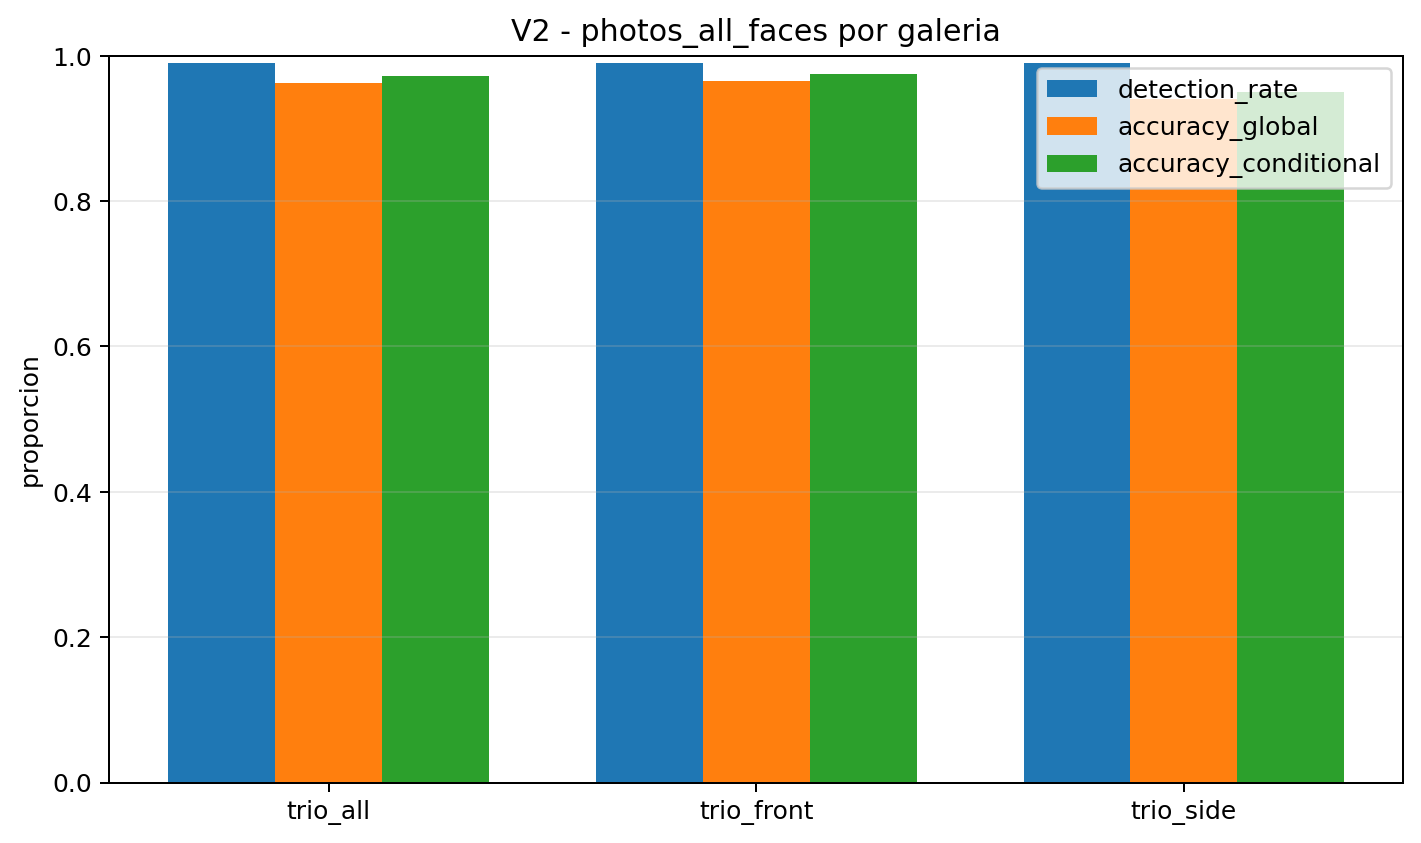

photos_all_bbox_f1_by_gallery.png


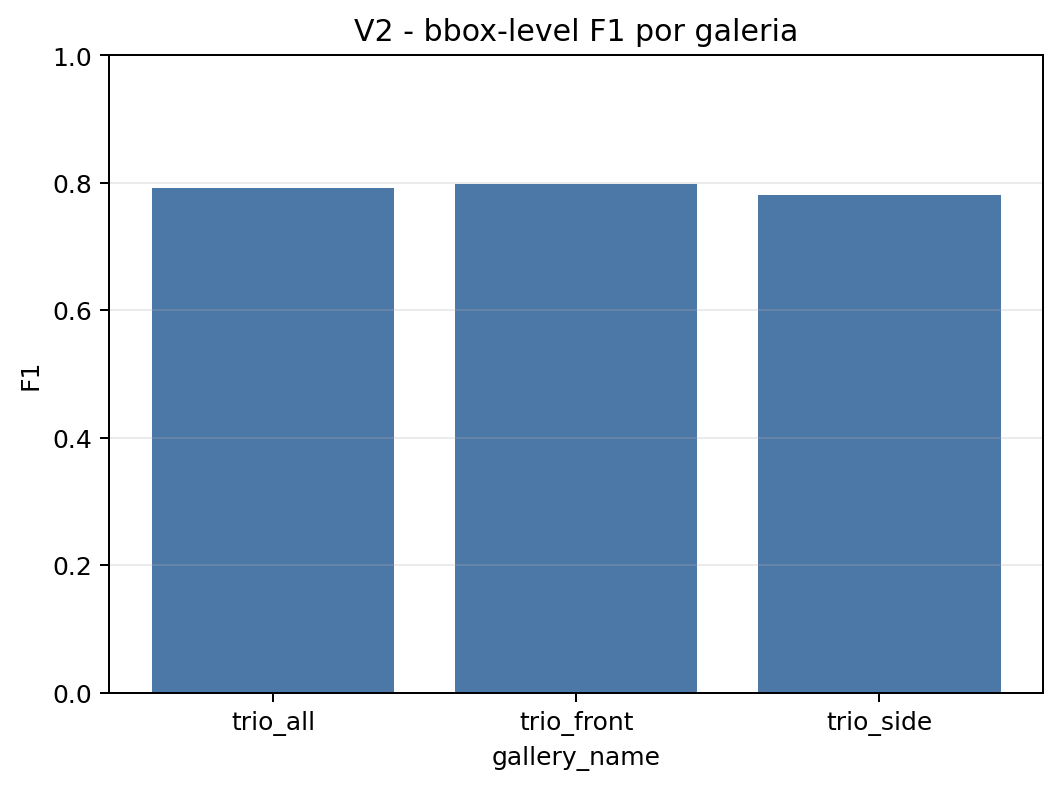

photos_all_bbox_precision_recall_f1_by_gallery.png


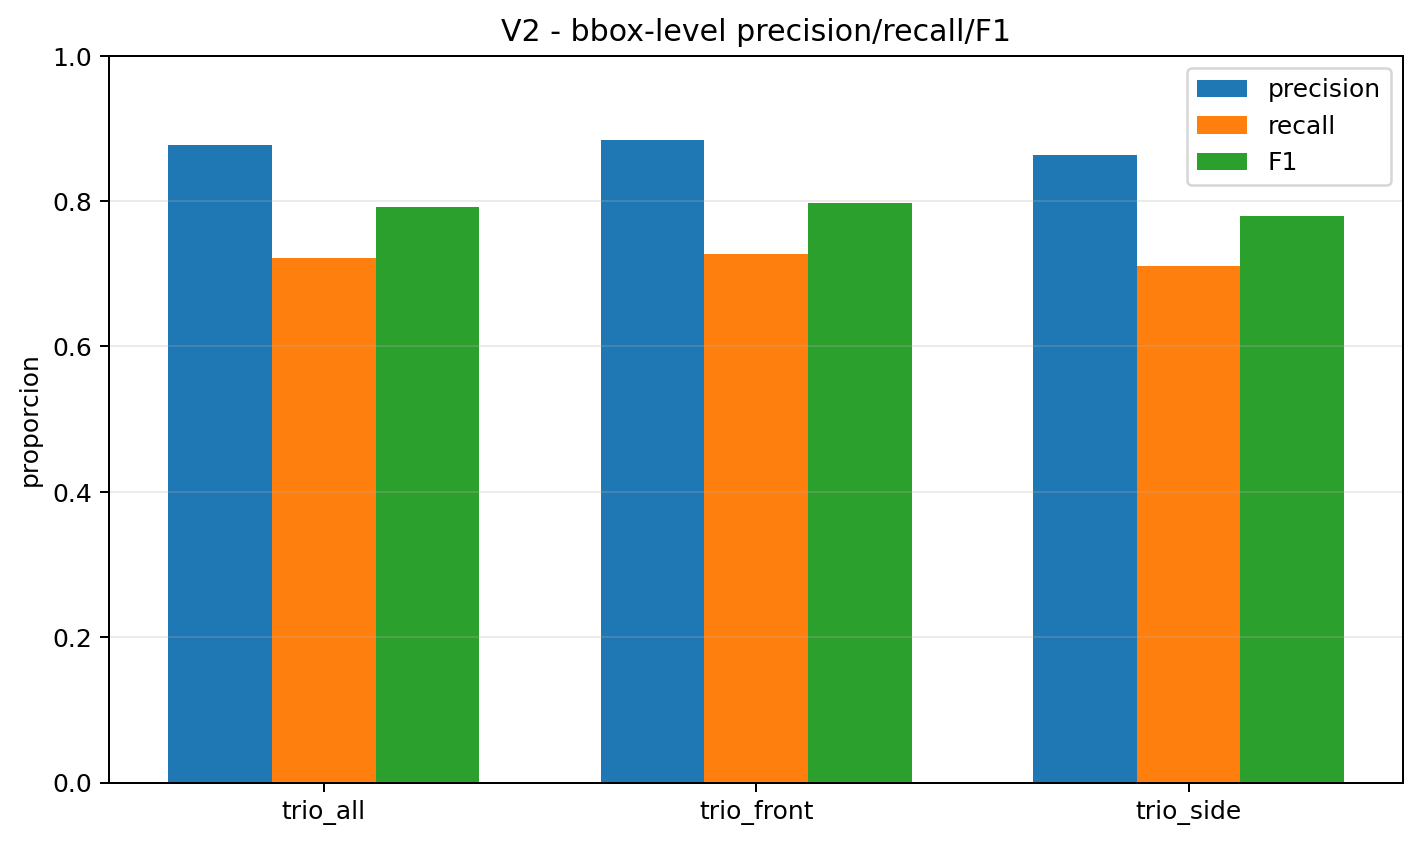

photos_all_bbox_tp_fp_fn_by_gallery.png


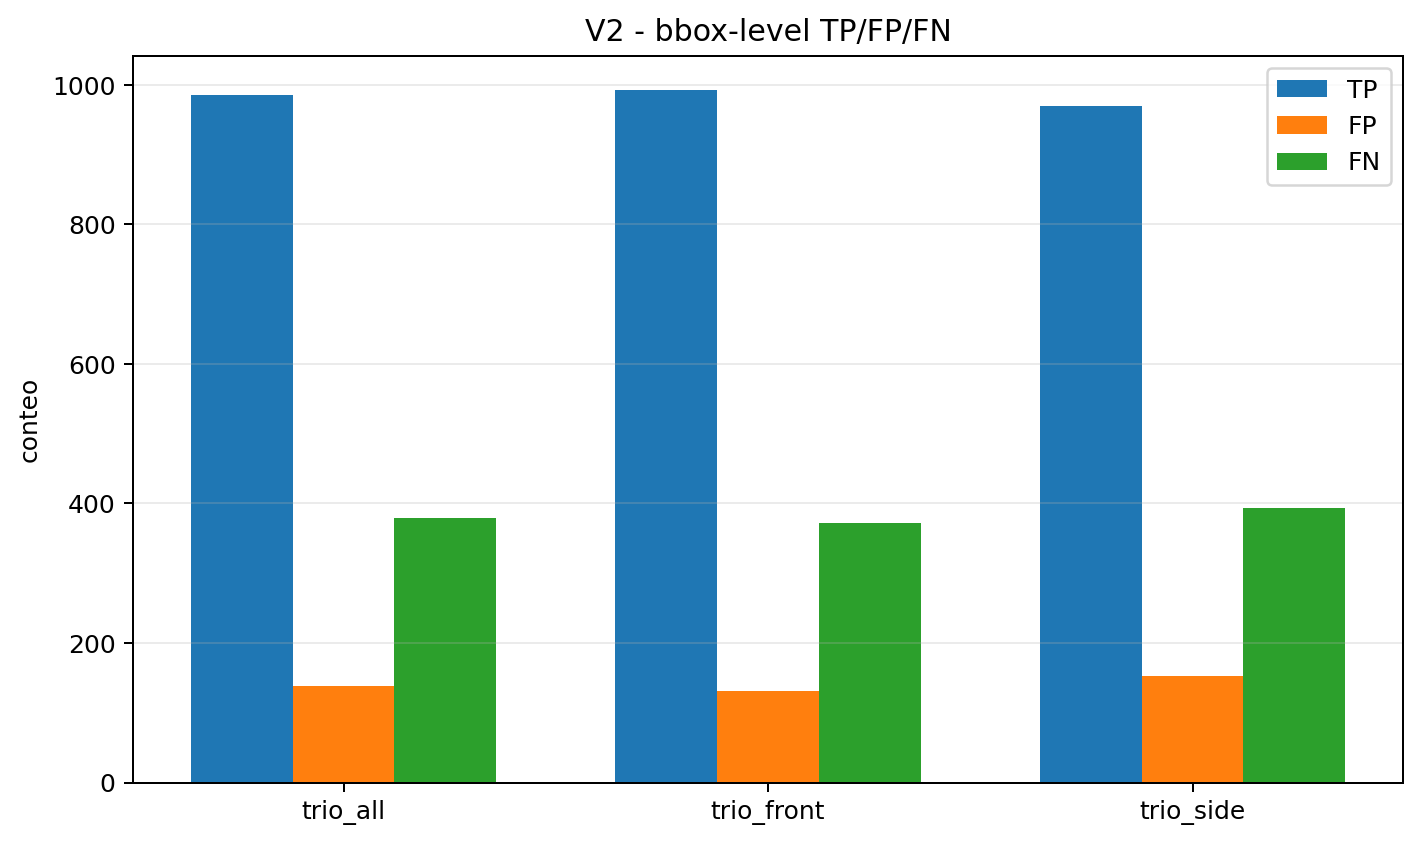

photos_all_bbox_f1_by_prefix.png


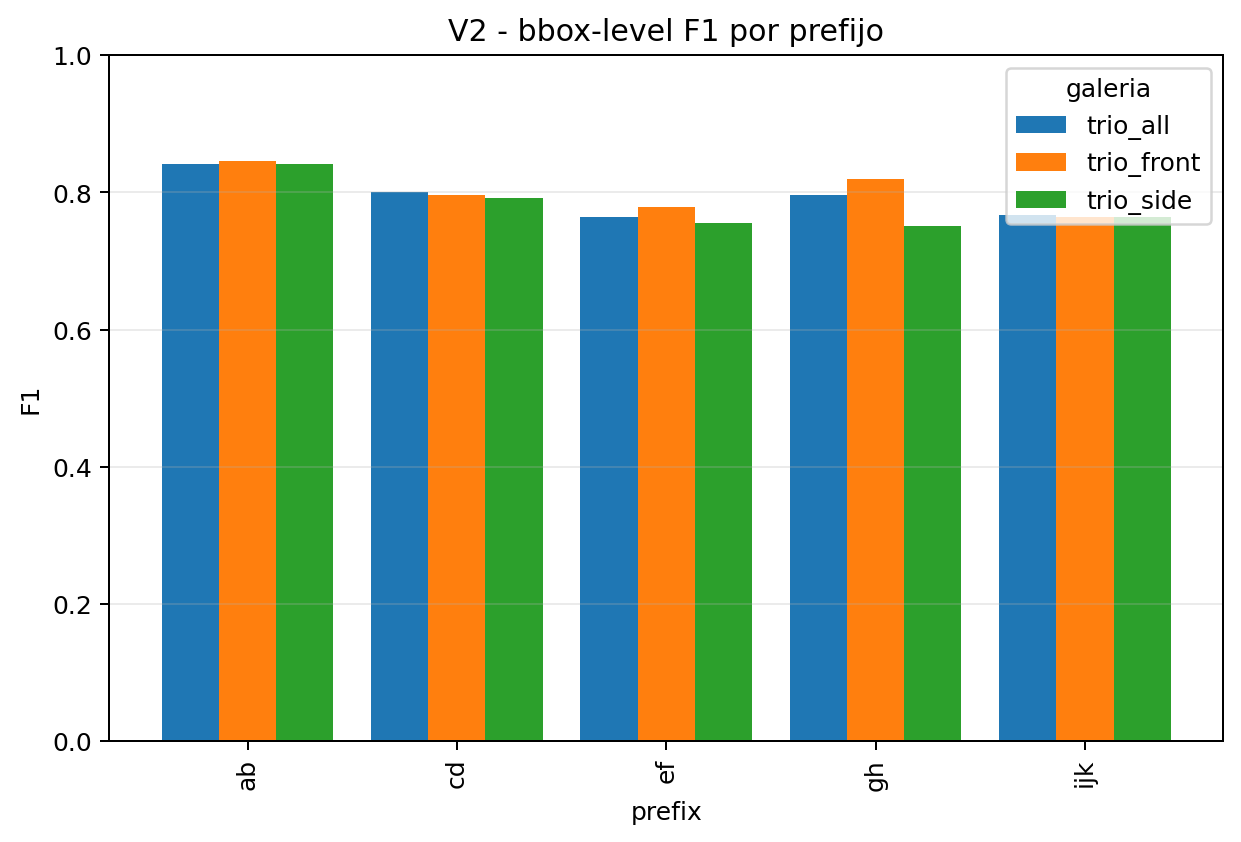

photos_all_bbox_f1_by_height.png


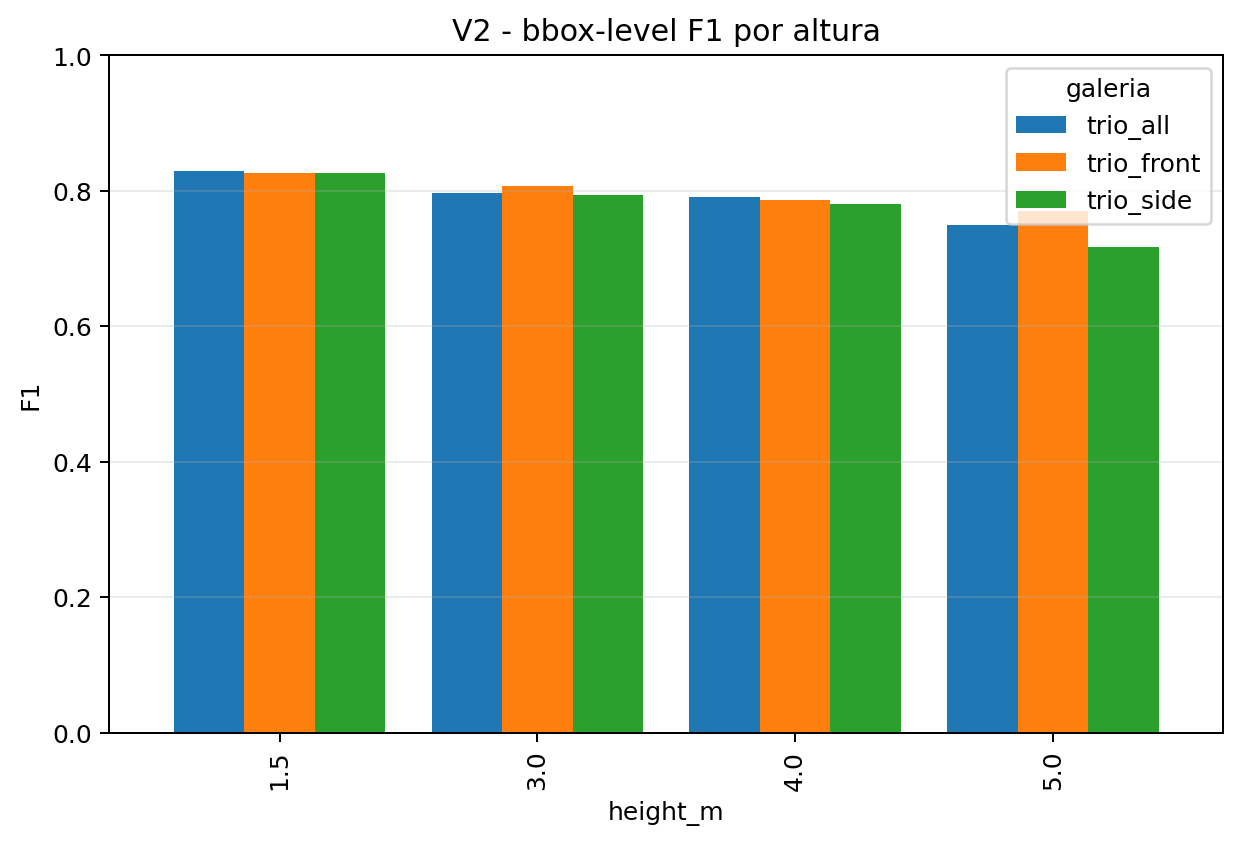

photos_all_bbox_f1_by_distance.png


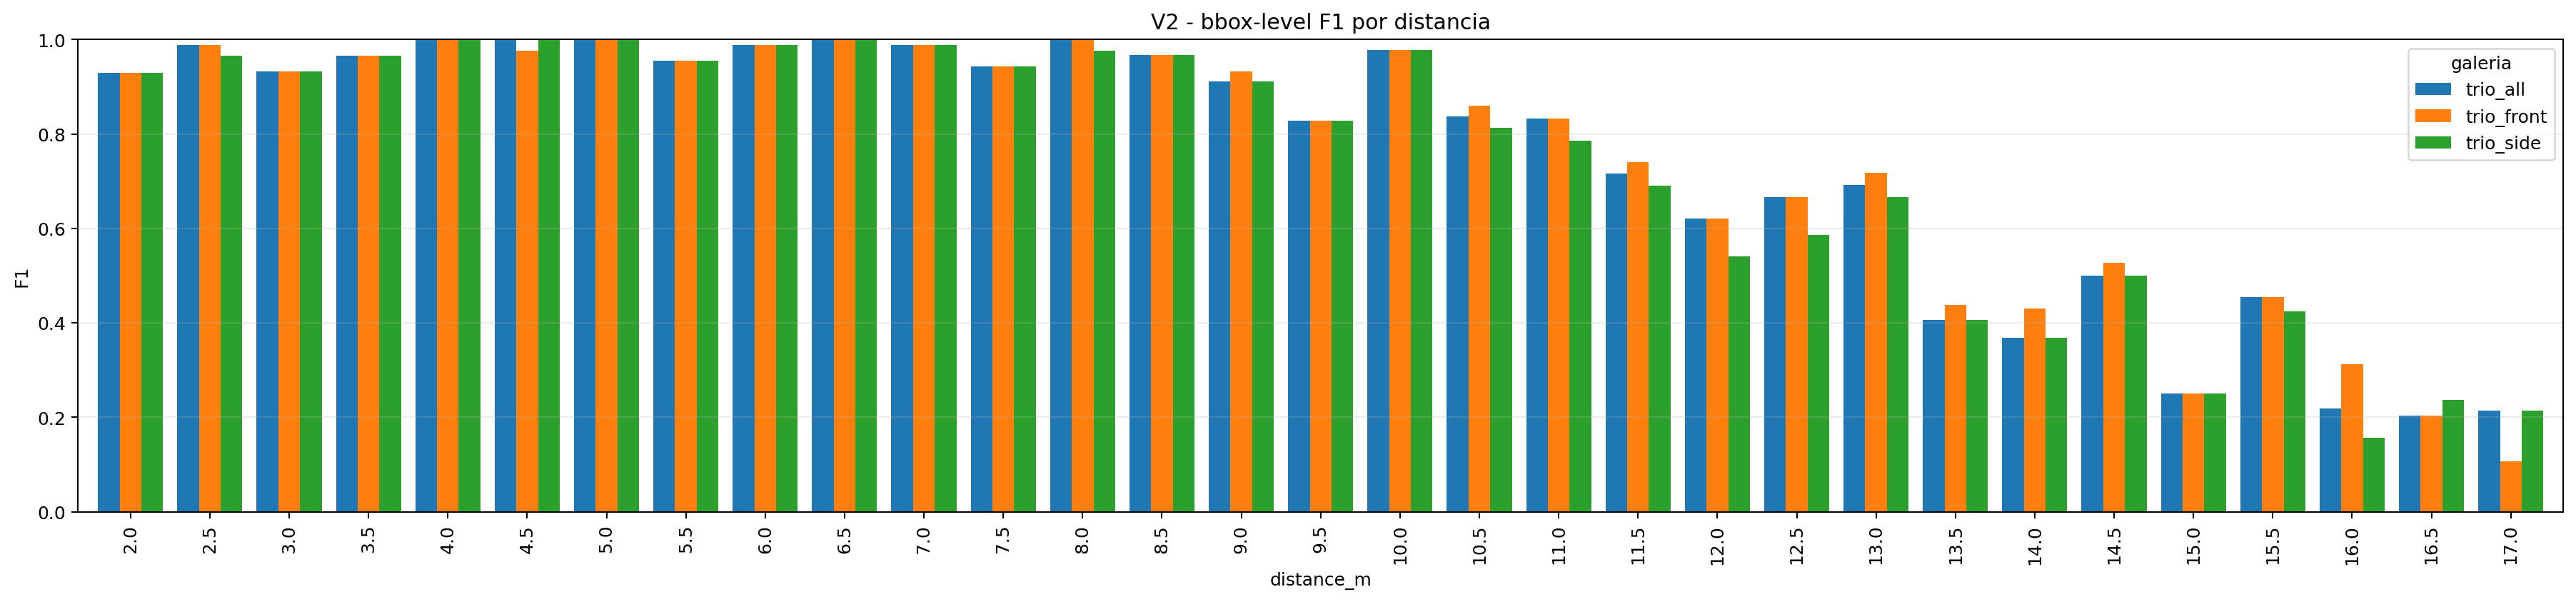

In [19]:
main_figures = [
    V2_FIGS_DIR / "metrics" / "photos_all_faces_pose_comparison.png",
    V2_FIGS_DIR / "metrics" / "photos_all_bbox_f1_by_gallery.png",
    V2_FIGS_DIR / "metrics" / "photos_all_bbox_precision_recall_f1_by_gallery.png",
    V2_FIGS_DIR / "metrics" / "photos_all_bbox_tp_fp_fn_by_gallery.png",
    V2_FIGS_DIR / "metrics" / "photos_all_bbox_f1_by_prefix.png",
    V2_FIGS_DIR / "metrics" / "photos_all_bbox_f1_by_height.png",
    V2_FIGS_DIR / "metrics" / "photos_all_bbox_f1_by_distance.png",
]

for fig_path in main_figures:
    if fig_path.exists():
        print(fig_path.name)
        display(NotebookImage(filename=str(fig_path)))
    else:
        print(f"No existe: {fig_path}")

## 9. Discusion y conclusiones

In [20]:
discussion_lines = []
discussion_lines.append("La version V2 usa galerias desde trio_cam + trio_gp y no hace fine-tuning de ArcFace.")
discussion_lines.append("El modo liviano permite regenerar tablas y graficos sin inicializar InsightFace ni repetir embeddings/detecciones.")
discussion_lines.append("No se reportan multiples runs porque el pipeline es deterministico bajo la configuracion actual.")

if not pose_comparison_df.empty:
    best_a = pose_comparison_df.sort_values("accuracy_global", ascending=False).iloc[0]
    discussion_lines.append(
        f"En photos_all_faces, la mejor galeria por accuracy_global fue {best_a['gallery_name']} "
        f"con {best_a['accuracy_global']:.2%}."
    )

if not full_set_summary_df.empty:
    best_b = full_set_summary_df.sort_values("expected_identity_recall_global", ascending=False).iloc[0]
    discussion_lines.append(
        f"En photos_all por conjunto, la mejor galeria por recall global fue {best_b['gallery_name']} "
        f"con {best_b['expected_identity_recall_global']:.2%}."
    )

if not bbox_top_df.empty:
    best_bbox = bbox_top_df.sort_values("f1", ascending=False).iloc[0]
    discussion_lines.append(
        f"En bbox-level, la mejor galeria por F1 fue {best_bbox['gallery_name']} "
        f"con F1={best_bbox['f1']:.2%}, precision={best_bbox['precision']:.2%}, recall={best_bbox['recall']:.2%}."
    )

for line in discussion_lines:
    print(f"- {line}")

summary_path = V2_TABLES_DIR / "v2_discussion_summary.txt"
summary_path.write_text("\n".join(discussion_lines), encoding="utf-8")
print(f"Resumen guardado en: {summary_path}")

- La version V2 usa galerias desde trio_cam + trio_gp y no hace fine-tuning de ArcFace.
- El modo liviano permite regenerar tablas y graficos sin inicializar InsightFace ni repetir embeddings/detecciones.
- No se reportan multiples runs porque el pipeline es deterministico bajo la configuracion actual.
- En photos_all_faces, la mejor galeria por accuracy_global fue trio_front con 96.48%.
- En photos_all por conjunto, la mejor galeria por recall global fue trio_front con 78.45%.
- En bbox-level, la mejor galeria por F1 fue trio_front con F1=79.77%, precision=88.33%, recall=72.73%.
Resumen guardado en: C:\Users\shipa\OneDrive\Escritorio\Otoño 2026\Procesamiento de imágenes\Proyecto_rostros\outputs_v2\tables\v2_discussion_summary.txt
